##  Power Spectrum

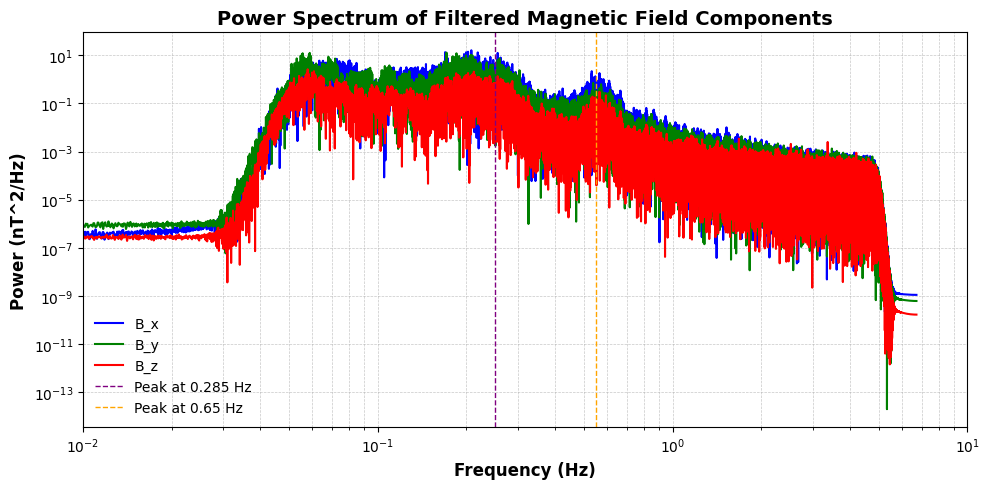

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.signal import butter, filtfilt

# Define the bandpass filter function
def bandpass_filter(data, lowcut, highcut, sampling_freq, order=8):
    nyquist = 0.5 * sampling_freq
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(order, [low, high], btype='band')
    return filtfilt(b, a, data)

# Filter data for the desired time range
start_time = pd.Timestamp('2015-10-28 13:00:00')
end_time = pd.Timestamp('2015-10-28 17:30:00')
filtered_df = df[(df['datetime'] >= start_time) & (df['datetime'] <= end_time)]

# Extract magnetic field and time values for all three components
b_x_filtered = filtered_df['b_x'].values
b_y_filtered = filtered_df['b_y'].values
b_z_filtered = filtered_df['b_z'].values
time_filtered = filtered_df['datetime']

# Sampling frequency
time_diff = np.diff(time_filtered).astype('timedelta64[ns]').astype(float) / 1e9  # Convert to seconds
sampling_freq = 1 / np.mean(time_diff)  # Hz

# Define the bandpass filter frequency range
lowcut = 0.05  # Low frequency (mHz)
highcut = 5 # High frequency (Hz)

# Apply bandpass filter to each magnetic field component
b_x_filtered_filtered = bandpass_filter(b_x_filtered, lowcut, highcut, sampling_freq)
b_y_filtered_filtered = bandpass_filter(b_y_filtered, lowcut, highcut, sampling_freq)
b_z_filtered_filtered = bandpass_filter(b_z_filtered, lowcut, highcut, sampling_freq)

# Function to compute FFT and Power Spectrum
def compute_fft(b_field):
    n = len(b_field)  # Number of samples
    fft_result = np.fft.fft(b_field)/n  # Compute FFT
    fft_freqs = np.fft.fftfreq(n, d=1/sampling_freq)  # Compute FFT frequencies
    fft_power = np.abs(fft_result)**2*n  # Compute Power Spectrum
    return fft_freqs, fft_power

# Compute FFT and Power Spectrum for all three components
fft_freqs, power_b_x = compute_fft(b_x_filtered_filtered)
_, power_b_y = compute_fft(b_y_filtered_filtered)
_, power_b_z = compute_fft(b_z_filtered_filtered)

# Use only the positive frequencies
positive_freqs = fft_freqs[:len(fft_freqs)//2]
positive_power_b_x = power_b_x[:len(power_b_x)//2]
positive_power_b_y = power_b_y[:len(power_b_y)//2]
positive_power_b_z = power_b_z[:len(power_b_z)//2]

# Plot Power Spectrum for all three components
plt.figure(figsize=(10, 5))
plt.loglog(positive_freqs, positive_power_b_x, color='blue', label='B_x')
plt.loglog(positive_freqs, positive_power_b_y, color='green', label='B_y')
plt.loglog(positive_freqs, positive_power_b_z, color='red', label='B_z')



# Add vertical lines at 0.5 Hz and 0.8 Hz
plt.axvline(x=0.25, color='purple', linestyle='--', linewidth=1, label='Peak at 0.285 Hz')
plt.axvline(x=0.55, color='orange', linestyle='--', linewidth=1, label='Peak at 0.65 Hz')



# Add labels and title
plt.xlabel('Frequency (Hz)', fontsize=12, fontweight='bold')
plt.ylabel('Power (nT^2/Hz)', fontsize=12, fontweight='bold')
plt.title('Power Spectrum of Filtered Magnetic Field Components', fontsize=14, fontweight='bold')
plt.xlim(1e-2,1e1)
# Add grid and legend
plt.grid(which='both', linestyle='--', linewidth=0.5, alpha=0.7)
plt.legend(frameon=False, fontsize=10)

# Show the plot
plt.tight_layout()
plt.show()


Fitted line equation (log-log): ln(P) = 5.792 * ln(f) + 14.067


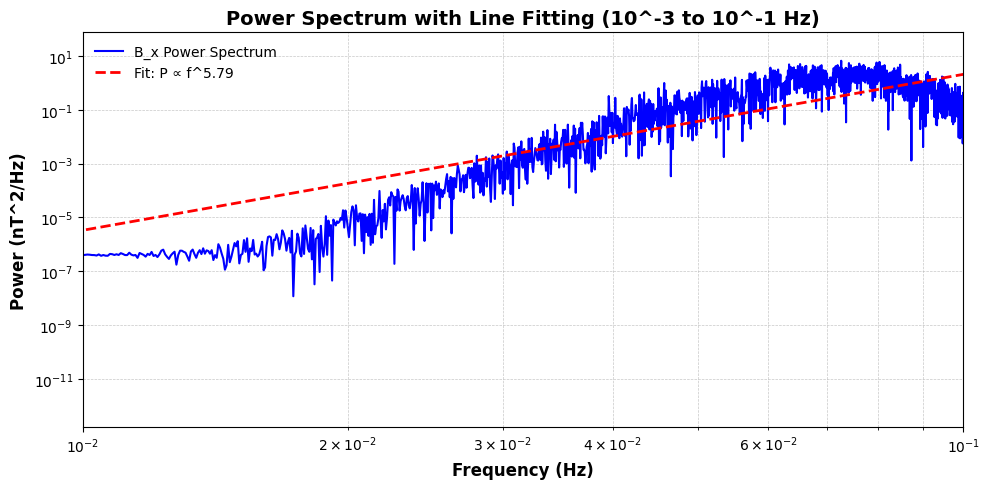

In [7]:
# Filter data for the range 10^-3 to 10^-1 Hz
range_mask = (positive_freqs >= 1e-3) & (positive_freqs <= 1e-1)
freqs_in_range = positive_freqs[range_mask]
power_b_x_in_range = positive_power_b_x[range_mask]

# Log-transform the data
ln_freqs = np.log(freqs_in_range)
ln_power = np.log(power_b_x_in_range)

# Perform linear regression
coefficients = np.polyfit(ln_freqs, ln_power, 1)  # Fit ln(P) = m * ln(f) + c
slope = coefficients[0]  # Slope (m)
intercept = coefficients[1]  # Intercept (c)

# Print the fitted equation
print(f"Fitted line equation (log-log): ln(P) = {slope:.3f} * ln(f) + {intercept:.3f}")

# Generate the fitted line in the original scale
fitted_power = np.exp(intercept) * freqs_in_range**slope

# Plot Power Spectrum with the fitted line
plt.figure(figsize=(10, 5))
plt.loglog(positive_freqs, positive_power_b_x, color='blue', label='B_x Power Spectrum')
plt.loglog(freqs_in_range, fitted_power, color='red', linestyle='--', linewidth=2, label=f'Fit: P ∝ f^{slope:.2f}')

# Add labels and title
plt.xlabel('Frequency (Hz)', fontsize=12, fontweight='bold')
plt.ylabel('Power (nT^2/Hz)', fontsize=12, fontweight='bold')
plt.title('Power Spectrum with Line Fitting (10^-3 to 10^-1 Hz)', fontsize=14, fontweight='bold')
plt.xlim(1e-2, 1e-1)  # Focus on the fitting range
plt.grid(which='both', linestyle='--', linewidth=0.5, alpha=0.7)
plt.legend(frameon=False, fontsize=10)

# Show the plot
plt.tight_layout()
plt.show()


Fitted line equation (log-log): ln(P) = 7.790 * ln(f) + 19.939


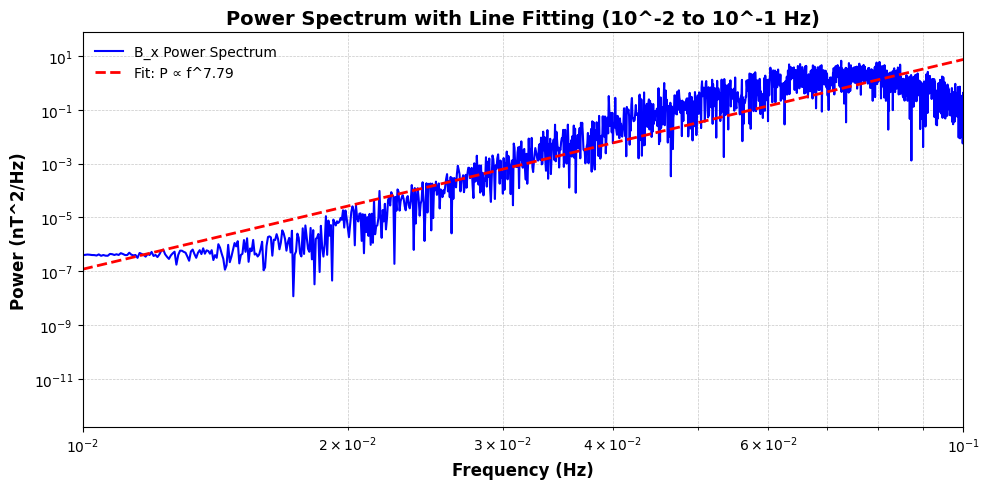

In [8]:
# Filter data for the range 10^-2 to 10^-1 Hz
range_mask = (positive_freqs >= 1e-2) & (positive_freqs <= 1e-1)
freqs_in_range = positive_freqs[range_mask]
power_b_x_in_range = positive_power_b_x[range_mask]

# Log-transform the data
ln_freqs = np.log(freqs_in_range)
ln_power = np.log(power_b_x_in_range)

# Perform linear regression
coefficients = np.polyfit(ln_freqs, ln_power, 1)  # Fit ln(P) = m * ln(f) + c
slope = coefficients[0]  # Slope (m)
intercept = coefficients[1]  # Intercept (c)

# Print the fitted equation
print(f"Fitted line equation (log-log): ln(P) = {slope:.3f} * ln(f) + {intercept:.3f}")

# Generate the fitted line in the original scale
fitted_power = np.exp(intercept) * freqs_in_range**slope

# Plot Power Spectrum with the fitted line
plt.figure(figsize=(10, 5))
plt.loglog(positive_freqs, positive_power_b_x, color='blue', label='B_x Power Spectrum')
plt.loglog(freqs_in_range, fitted_power, color='red', linestyle='--', linewidth=2, label=f'Fit: P ∝ f^{slope:.2f}')

# Add labels and title
plt.xlabel('Frequency (Hz)', fontsize=12, fontweight='bold')
plt.ylabel('Power (nT^2/Hz)', fontsize=12, fontweight='bold')
plt.title('Power Spectrum with Line Fitting (10^-2 to 10^-1 Hz)', fontsize=14, fontweight='bold')
plt.xlim(1e-2, 1e-1)  # Focus on the fitting range
plt.grid(which='both', linestyle='--', linewidth=0.5, alpha=0.7)
plt.legend(frameon=False, fontsize=10)

# Show the plot
plt.tight_layout()
plt.show()


## Spectrogram with enhanced colours and time axis in HH:MM format

In [2]:
import pandas as pd
from spacepy import pycdf
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.signal import spectrogram

# Load the CDF file
cdf_path = '/home/draksha/pydata/mms1/fgm/srvy/l2/2015/10/mms1_fgm_srvy_l2_20151028_v4.18.0.cdf'
cdf = pycdf.CDF(cdf_path)

# Extract magnetic field data and timestamps
datetime = pd.to_datetime(cdf['Epoch'][:])
b_x = cdf['mms1_fgm_b_gse_srvy_l2'][:, 0]
b_y = cdf['mms1_fgm_b_gse_srvy_l2'][:, 1]
b_z = cdf['mms1_fgm_b_gse_srvy_l2'][:, 2]
b_t = np.linalg.norm([b_x, b_y, b_z], axis=0)

# Combine into a DataFrame
df = pd.DataFrame({
    'datetime': datetime,
    'b_x': b_x,
    'b_y': b_y,
    'b_z': b_z,
    'b_t': b_t
})

# Drop any NaN values
df.dropna(inplace=True)


In [3]:

# Filter data within the desired time range
start_time = pd.Timestamp('2015-10-28 13:00:00')
end_time = pd.Timestamp('2015-10-28 17:30:00')
df_filtered = df[(df['datetime'] >= start_time) & (df['datetime'] <= end_time)]

# Convert datetime to seconds relative to the start of the filtered range
time_in_seconds = (df_filtered['datetime'] - df_filtered['datetime'].iloc[0]).dt.total_seconds()

# Calculate sampling frequency
sampling_freq = 1 / np.mean(np.diff(time_in_seconds))

# Function to compute spectrogram
def compute_spectrogram(b_field, sampling_freq, nperseg=1024):
    f, t, Sxx = spectrogram(b_field, fs=sampling_freq, nperseg=nperseg)
    return f, t, Sxx

# Compute spectrograms for all components
f_b_x, t_b_x, Sxx_b_x = compute_spectrogram(df_filtered['b_x'].values, sampling_freq)
f_b_y, t_b_y, Sxx_b_y = compute_spectrogram(df_filtered['b_y'].values, sampling_freq)
f_b_z, t_b_z, Sxx_b_z = compute_spectrogram(df_filtered['b_z'].values, sampling_freq)
f_b_t, t_b_t, Sxx_b_t = compute_spectrogram(df_filtered['b_t'].values, sampling_freq)

# Convert spectrogram times to minutes
t_b_x_minutes = (t_b_x + time_in_seconds.iloc[0]) / 60
t_b_y_minutes = (t_b_y + time_in_seconds.iloc[0]) / 60
t_b_z_minutes = (t_b_z + time_in_seconds.iloc[0]) / 60
t_b_t_minutes = (t_b_t + time_in_seconds.iloc[0]) / 60



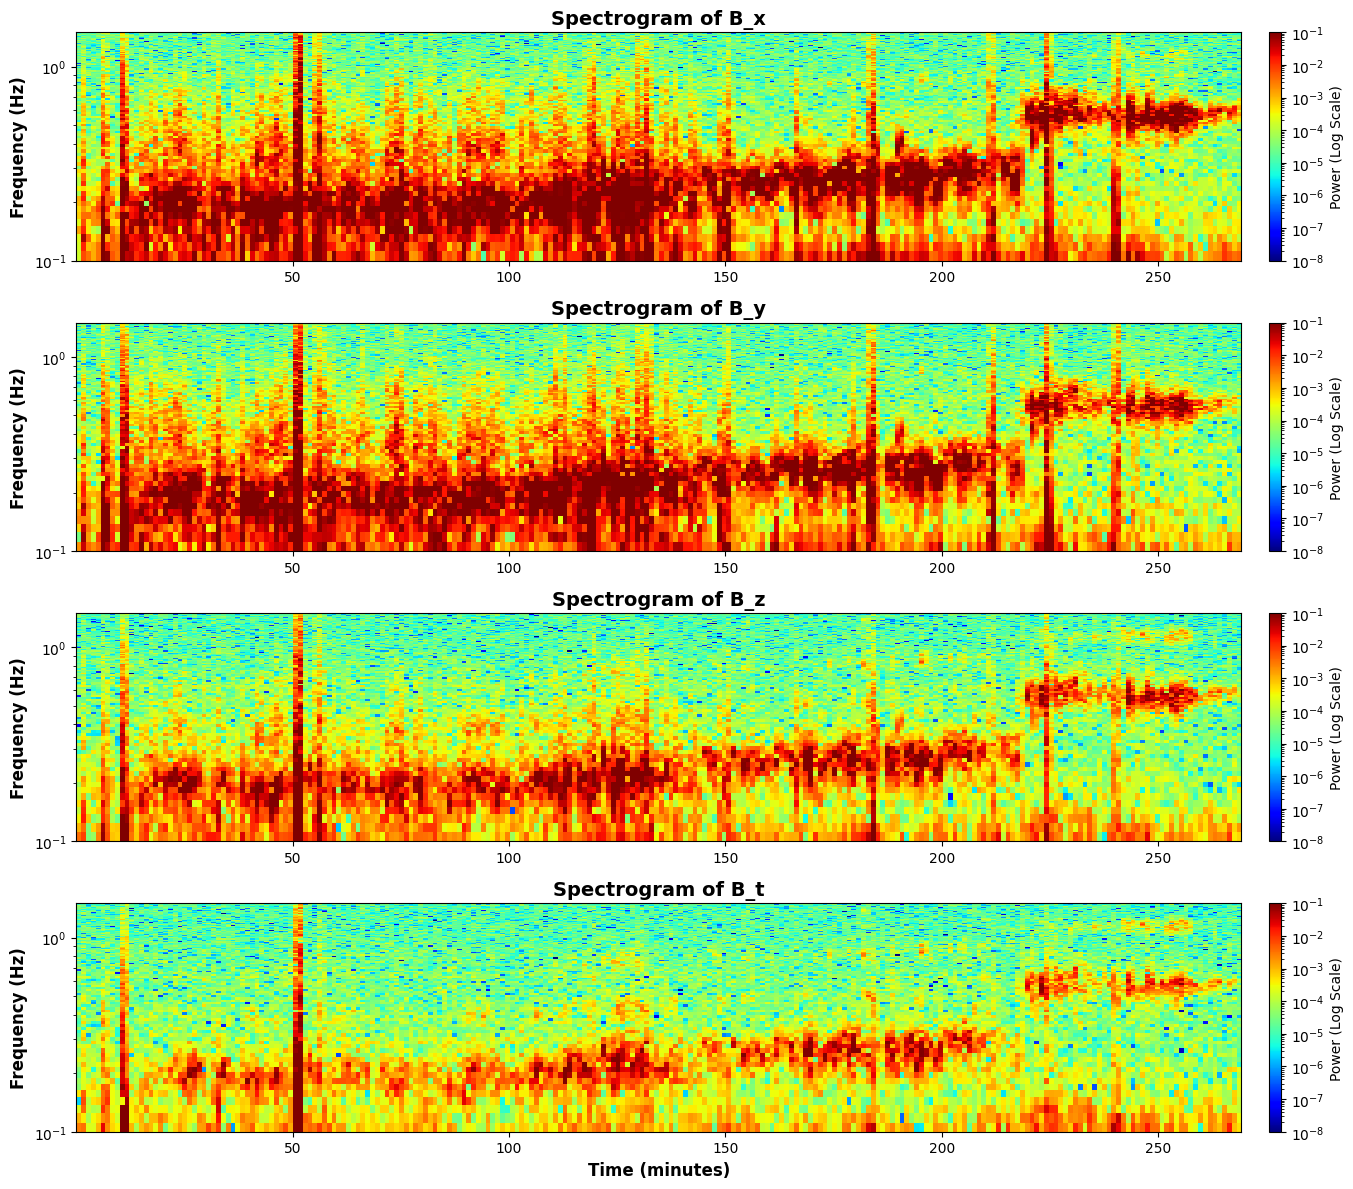

In [4]:
# Plot spectrograms for all components
plt.figure(figsize=(15, 12))

# Spectrogram for B_x
plt.subplot(4, 1, 1)
pcm_x = plt.pcolormesh(
    t_b_x_minutes, f_b_x, Sxx_b_x,
    shading='auto', cmap='jet',
    norm=LogNorm(vmin=1e-8, vmax=1e-1)
)
plt.yscale('log')
plt.ylim(0.1, 1.5)
plt.colorbar(pcm_x, label='Power (Log Scale)', pad=0.02)
plt.title('Spectrogram of B_x', fontsize=14, fontweight='bold')
plt.ylabel('Frequency (Hz)', fontsize=12, fontweight='bold')

# Spectrogram for B_y
plt.subplot(4, 1, 2)
pcm_y = plt.pcolormesh(
    t_b_y_minutes, f_b_y, Sxx_b_y,
    shading='auto', cmap='jet',
    norm=LogNorm(vmin=1e-8, vmax=1e-1)
)
plt.yscale('log')
plt.ylim(0.1, 1.5)
plt.colorbar(pcm_y, label='Power (Log Scale)', pad=0.02)
plt.title('Spectrogram of B_y', fontsize=14, fontweight='bold')
plt.ylabel('Frequency (Hz)', fontsize=12, fontweight='bold')

# Spectrogram for B_z
plt.subplot(4, 1, 3)
pcm_z = plt.pcolormesh(
    t_b_z_minutes, f_b_z, Sxx_b_z,
    shading='auto', cmap='jet',
    norm=LogNorm(vmin=1e-8, vmax=1e-1)
)
plt.yscale('log')
plt.ylim(0.1, 1.5)
plt.colorbar(pcm_z, label='Power (Log Scale)', pad=0.02)
plt.title('Spectrogram of B_z', fontsize=14, fontweight='bold')
plt.ylabel('Frequency (Hz)', fontsize=12, fontweight='bold')

# Spectrogram for B_t (optional)
plt.subplot(4, 1, 4)
pcm_t = plt.pcolormesh(
    t_b_t_minutes, f_b_t, Sxx_b_t,
    shading='auto', cmap='jet',
    norm=LogNorm(vmin=1e-8, vmax=1e-1)
)
plt.yscale('log')
plt.ylim(0.1, 1.5)
plt.colorbar(pcm_t, label='Power (Log Scale)', pad=0.02)
plt.title('Spectrogram of B_t', fontsize=14, fontweight='bold')
plt.xlabel('Time (minutes)', fontsize=12, fontweight='bold')
plt.ylabel('Frequency (Hz)', fontsize=12, fontweight='bold')

# Adjust layout
plt.tight_layout()
plt.show()


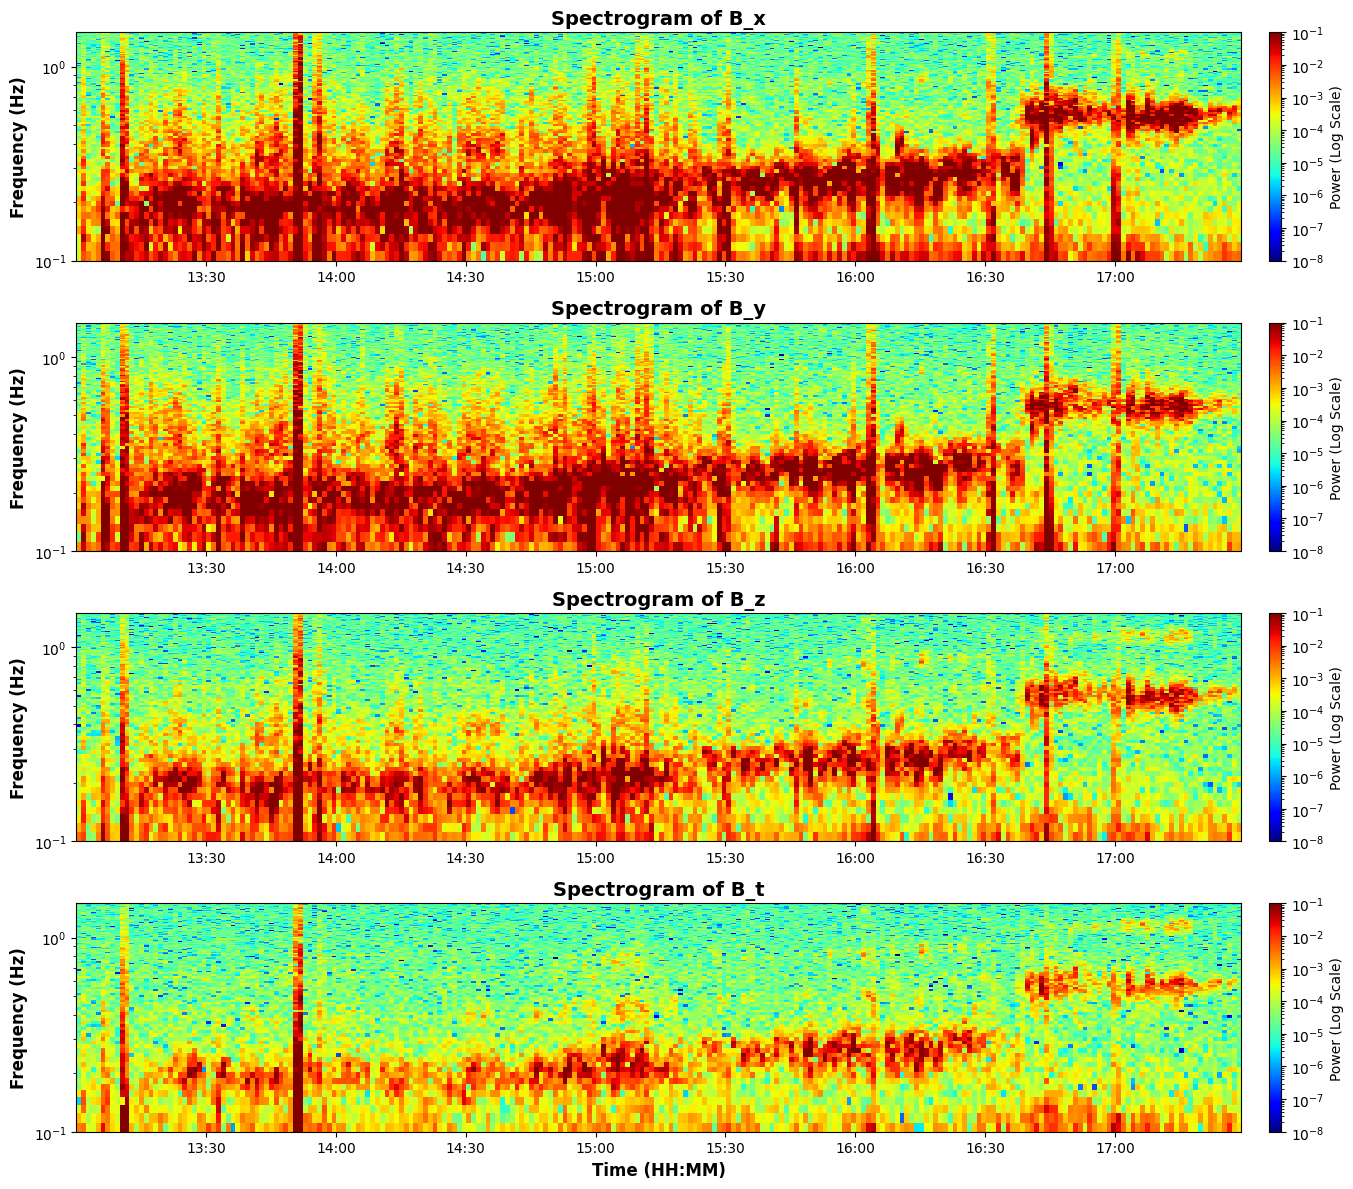

In [5]:
import matplotlib.dates as mdates

# Update spectrogram time arrays to be datetime values for formatting
t_b_x_datetime = pd.to_datetime(df_filtered['datetime'].iloc[0]) + pd.to_timedelta(t_b_x, unit='s')
t_b_y_datetime = pd.to_datetime(df_filtered['datetime'].iloc[0]) + pd.to_timedelta(t_b_y, unit='s')
t_b_z_datetime = pd.to_datetime(df_filtered['datetime'].iloc[0]) + pd.to_timedelta(t_b_z, unit='s')
t_b_t_datetime = pd.to_datetime(df_filtered['datetime'].iloc[0]) + pd.to_timedelta(t_b_t, unit='s')

# Plot spectrograms for all components
plt.figure(figsize=(15, 12))

# Spectrogram for B_x
plt.subplot(4, 1, 1)
pcm_x = plt.pcolormesh(
    t_b_x_datetime, f_b_x, Sxx_b_x,
    shading='auto', cmap='jet',
    norm=LogNorm(vmin=1e-8, vmax=1e-1)
)
plt.yscale('log')
plt.ylim(0.1, 1.5)
plt.colorbar(pcm_x, label='Power (Log Scale)', pad=0.02)
plt.title('Spectrogram of B_x', fontsize=14, fontweight='bold')
plt.ylabel('Frequency (Hz)', fontsize=12, fontweight='bold')
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

# Spectrogram for B_y
plt.subplot(4, 1, 2)
pcm_y = plt.pcolormesh(
    t_b_y_datetime, f_b_y, Sxx_b_y,
    shading='auto', cmap='jet',
    norm=LogNorm(vmin=1e-8, vmax=1e-1)
)
plt.yscale('log')
plt.ylim(0.1, 1.5)
plt.colorbar(pcm_y, label='Power (Log Scale)', pad=0.02)
plt.title('Spectrogram of B_y', fontsize=14, fontweight='bold')
plt.ylabel('Frequency (Hz)', fontsize=12, fontweight='bold')
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

# Spectrogram for B_z
plt.subplot(4, 1, 3)
pcm_z = plt.pcolormesh(
    t_b_z_datetime, f_b_z, Sxx_b_z,
    shading='auto', cmap='jet',
    norm=LogNorm(vmin=1e-8, vmax=1e-1)
)
plt.yscale('log')
plt.ylim(0.1, 1.5)
plt.colorbar(pcm_z, label='Power (Log Scale)', pad=0.02)
plt.title('Spectrogram of B_z', fontsize=14, fontweight='bold')
plt.ylabel('Frequency (Hz)', fontsize=12, fontweight='bold')
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

# Spectrogram for B_t
plt.subplot(4, 1, 4)
pcm_t = plt.pcolormesh(
    t_b_t_datetime, f_b_t, Sxx_b_t,
    shading='auto', cmap='jet',
    norm=LogNorm(vmin=1e-8, vmax=1e-1)
)
plt.yscale('log')
plt.ylim(0.1, 1.5)
plt.colorbar(pcm_t, label='Power (Log Scale)', pad=0.02)
plt.title('Spectrogram of B_t', fontsize=14, fontweight='bold')
plt.xlabel('Time (HH:MM)', fontsize=12, fontweight='bold')
plt.ylabel('Frequency (Hz)', fontsize=12, fontweight='bold')
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

# Adjust layout
plt.tight_layout()
plt.show()
